# Nuclear
*Neutron transport: one lane per history*

A beam of neutrons hits a slab. Each neutron flies, collides, and either scatters on, is absorbed, or leaves through one face; the fractions that do each are what a shield or a reflector design needs. This page runs one lane per neutron history, checks the fractions against a deterministic solution, and takes the sensitivity of each fraction to the cross-section.

**Time:** ~5 min &middot; **Runs on:** CPU (same code on GPU) &middot;
**You need:** hawk, eagle, NumPy and matplotlib; read first: [hawk in your domain](../vocabulary)

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "hawk"
    for rel in (
        "docs/content/_shared/anim.py",
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/hawk/{ref}/{rel}", root / rel)
    (root / "docs/content/vocabulary").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/vocabulary")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "_shared"))
from nb_helpers import gpu_available, on_device, plot_style, show, to_numpy, xp
plot_style()

## The slab, once

A slab of thickness `width` (cm) fills `0 < x < width`. A plane beam of neutrons enters at `x = 0` moving straight in, one neutron per history. One energy group, isotropic scattering, no fission: the model leaves out energy dependence, anisotropy and multiplication.

- The **total cross-section** `sigma_t` (1/cm) is the chance per unit path of a collision. A free flight has length `s = -ln(u) / sigma_t` with `u` uniform on (0, 1).
- At a collision the neutron **scatters** with probability `c = sigma_s / sigma_t` (the scattering ratio), into a new direction `mu` uniform on (-1, 1), or is **absorbed**.
- A flight that carries it past `x = width` is **transmitted**, past `x = 0` **reflected**. Every history ends in exactly one of transmitted, reflected or absorbed.
- Lengths are in cm, so `sigma_t = 1` makes a thickness in cm also a thickness in mean free paths.

Random numbers come from hawk's counter-based generator, `hawk.math.random`: a draw is a pure function of a `seed` and a `counter`. The seed is the history number and the counter numbers the draws within it, so a history is the same on every run, on a CPU or a GPU, and two runs with different cross-sections see the same random numbers (common random numbers). [Monte Carlo](12_monte_carlo_ensemble) draws its starting values in NumPy instead; here the number of draws per history is not known in advance, so the draws happen inside the kernel.

One more word is declared for the gradient below: flights are drawn from a **sampling** cross-section `sigma_ref`, while the tally is evaluated at `sigma_t`. When they are equal the two never differ.

In [3]:
import numpy as np
import eagle
import hawk
import hawk.math as m
from hawk import Index, Mutable, Param, Scalar
from hawk.ext import DATA_ONLY, KernelKind


class Slab(KernelKind, slug="slab"):
    seed: Index[np.int64]       # the history number: with a draw counter, it fixes every random number
    width: Scalar       # slab thickness (cm); one per lane, so a sweep is one call
    c: Param            # scattering ratio sigma_s / sigma_t
    sigma_t: Param      # total cross-section the tally is evaluated at (1/cm)
    sigma_ref: Param    # total cross-section the flights are drawn from (1/cm)
    guard = DATA_ONLY

Slab

__main__.Slab

## One history

The body is the history as you would tell it: fly, then branch on what happened. `if / elif / else` picks leaking right, leaking left, or colliding, and a collision branches again into scatter or absorb. A finished history sets `alive = 0` and leaves the loop at the top of its next trip. At most 120 collisions are allowed; the sweep below checks that no history needs more.

`log_w` is the log of the **likelihood ratio** `w`: the probability density of the history's flights at `sigma_t`, divided by the one they were drawn from, at `sigma_ref`. Each collision multiplies it by `sigma_t e^(-sigma_t s) / (sigma_ref e^(-sigma_ref s))`, and the final flight that leaves the slab by the ratio of the survival probabilities over the distance `dist` to the face. A tally is `w` for the history's fate and 0 for the others, so its mean is the expected fraction at `sigma_t` even though the flights were drawn at `sigma_ref`. At `sigma_t = sigma_ref`, `w = 1` and the tallies are the plain 0 or 1.

In [4]:
@Slab
def history(seed, width, c, sigma_t, sigma_ref,
            through: Mutable[Scalar], back: Mutable[Scalar], absorbed: Mutable[Scalar], unfinished: Mutable[Scalar]):
    x = 0.0
    mu = 1.0
    alive = 1.0
    log_w = 0.0
    through = 0.0
    back = 0.0
    absorbed = 0.0
    s = 0.0
    x_new = 0.0
    dist = 0.0
    for i in range(120):
        if alive < 0.5:                                                 # a finished history leaves the loop
            break
        s = m.random.exponential(seed, 3 * i, sigma_ref)            # free flight
        x_new = x + mu * s
        if x_new > width:                                           # leaves through the far face
            dist = (width - x) / mu
            log_w = log_w - (sigma_t - sigma_ref) * dist
            through = m.exp(log_w)
            alive = 0.0
        elif x_new < 0.0:                                           # leaves back through the near face
            dist = x / (-mu)
            log_w = log_w - (sigma_t - sigma_ref) * dist
            back = m.exp(log_w)
            alive = 0.0
        else:                                                       # collides at x_new
            x = x_new
            log_w = log_w + m.log(sigma_t / sigma_ref) - (sigma_t - sigma_ref) * s
            if m.random.uniform(seed, 3 * i + 1) < c:               # scatters: a new direction
                mu = m.random.uniform(seed, 3 * i + 2, -1.0, 1.0)
            else:                                                   # absorbed
                absorbed = m.exp(log_w)
                alive = 0.0
    unfinished = alive


history

<Kernel history slots=9>

## A sweep of thicknesses

Twelve thicknesses from 0.5 to 6 cm (0.5 to 6 mean free paths), at `sigma_t = 1` per cm and `c = 0.7`, 100 000 histories each: 1.2 million lanes, one call. `eagle.deploy(history).run(...)` takes the planes and parameters by name and returns the tallies by name.

In [5]:
SIGMA, C, N = 1.0, 0.7, 100_000
widths = np.arange(1, 13) * 0.5                              # cm
K = len(widths)
lane_width = np.repeat(widths, N)
lane_seed = np.arange(K * N, dtype=np.int64)                 # every lane is its own history

transport = eagle.deploy(history)


def sweep(sigma=SIGMA, sampled=None, c=C):
    sampled = sigma if sampled is None else sampled
    return transport.run(seed=lane_seed, width=lane_width, c=c, sigma_t=sigma, sigma_ref=sampled, returns="numpy")


def per_width(plane, N=N):
    return plane.reshape(-1, N)                  # (thickness, history)


out = sweep()
assert (out["unfinished"] == 0).all(), "every history ended within 120 collisions"
fractions = np.stack([per_width(out[k]).mean(axis=1) for k in ("through", "back", "absorbed")], axis=1)   # (thickness, fate)
error = np.sqrt(fractions * (1 - fractions) / N)             # one standard error of a fraction: sqrt(p (1 - p) / N)
print("thickness (cm)  transmitted  reflected  absorbed")
for L, f in list(zip(widths, fractions))[::3]:
    print(f"{L:14.1f}  {f[0]:11.4f}  {f[1]:9.4f}  {f[2]:8.4f}")

thickness (cm)  transmitted  reflected  absorbed
           0.5       0.7154     0.1155    0.1691
           2.0       0.2423     0.1998    0.5580
           3.5       0.0772     0.2062    0.7167
           5.0       0.0244     0.2087    0.7669


## Check it against what is known

Two checks. The first is exact. With no scattering (`c = 0`) every collision absorbs, so the transmitted fraction is the chance of a flight longer than the slab, `exp(-sigma_t width)`, and nothing is reflected. A fraction estimated from `N` histories has a standard error of `sqrt(p (1 - p) / N)`; the check allows four of them.

The second holds by construction: each history ends in exactly one fate, so transmitted, reflected and absorbed add to one on every history. It catches a lane that is lost or counted twice, not a wrong physics.

In [6]:
pure = sweep(c=0.0)
T = per_width(pure["through"]).mean(axis=1)
exact = np.exp(-SIGMA * widths)
z = (T - exact) / np.sqrt(exact * (1 - exact) / N)
assert np.abs(z).max() < 4 and (pure["back"] == 0).all(), z
print(f"purely absorbing slab: transmitted fraction against exp(-sigma_t width), worst deviation {np.abs(z).max():.1f} standard errors")

assert np.array_equal(out["through"] + out["back"] + out["absorbed"], np.ones(K * N))
print("every history ended in exactly one fate: transmitted + reflected + absorbed = 1")

purely absorbing slab: transmitted fraction against exp(-sigma_t width), worst deviation 1.5 standard errors
every history ended in exactly one fate: transmitted + reflected + absorbed = 1


## Check it against a deterministic solution

For the scattering slab there is no closed form, so the reference is a deterministic discrete-ordinates solution of the same problem: the transport equation on a fine grid of cells and 64 directions, the uncollided beam done exactly, and the scattered part by source iteration. It shares nothing with the sampling, so agreement is a real test of the physics. Its own discretisation error is checked first: refining the grid and the directions moves the answer by about 1e-4 from a coarse setting (100 cells, 32 directions) and by under 2e-5 from the setting used, far below the Monte Carlo error of about 1e-3.

In [7]:
def discrete_ordinates(L, sigma, c, cells=200, directions=64, tol=1e-12):
    # returns [transmitted, reflected, absorbed] for a unit normal beam: the exponential step through each cell
    mu, w = np.polynomial.legendre.leggauss(directions)
    right = mu > 0
    h = L / cells
    x = (np.arange(cells) + 0.5) * h
    tau = sigma * h / np.abs(mu)
    atten = np.exp(-tau)
    mean_factor = (1 - atten) / tau
    first = 0.5 * c * sigma * np.exp(-sigma * x)                  # scattering source of the uncollided beam
    phi = np.zeros(cells)
    for _ in range(1000):
        source = (0.5 * c * sigma * phi + first) / sigma
        psi_cell = np.zeros((directions, cells))
        psi = np.zeros(directions)
        for i in range(cells):                                    # sweep to the right for mu > 0
            psi_cell[right, i] = source[i] + (psi[right] - source[i]) * mean_factor[right]
            psi[right] = psi[right] * atten[right] + source[i] * (1 - atten[right])
        leaving_right = psi.copy()
        psi = np.zeros(directions)
        for i in range(cells - 1, -1, -1):                        # sweep to the left for mu < 0
            psi_cell[~right, i] = source[i] + (psi[~right] - source[i]) * mean_factor[~right]
            psi[~right] = psi[~right] * atten[~right] + source[i] * (1 - atten[~right])
        new = (w[:, None] * psi_cell).sum(axis=0)
        converged = np.abs(new - phi).max() < tol
        phi = new
        if converged:
            break
    T = np.exp(-sigma * L) + (w * mu * leaving_right)[right].sum()
    R = -(w * mu * psi)[~right].sum()
    return np.array([T, R, 1 - T - R])


coarse, fine = discrete_ordinates(2.0, SIGMA, C, 100, 32), discrete_ordinates(2.0, SIGMA, C, 400, 64)
print("reference at 2 cm, coarse and fine:", coarse.round(5), fine.round(5))
assert np.abs(coarse - fine).max() < 2e-4 and np.abs(discrete_ordinates(2.0, SIGMA, C) - fine).max() < 2e-5

reference = np.array([discrete_ordinates(L, SIGMA, C) for L in widths])
z = (fractions - reference) / error
Z_MAX = 4.0
assert np.abs(z).max() < Z_MAX, z
print(f"Monte Carlo against the reference, {z.size} fractions: worst deviation {np.abs(z).max():.1f} standard errors < {Z_MAX:g}")

reference at 2 cm, coarse and fine: [0.24148 0.20003 0.55849] [0.24146 0.19996 0.55858]


Monte Carlo against the reference, 36 fractions: worst deviation 1.9 standard errors < 4


## How the error falls with the number of histories

Monte Carlo is first order in `1 / sqrt(N)`: ten times the histories, a third of the error. To measure it, run many independent batches of `N` histories at 2 cm, and compare the spread of their transmitted fractions with `sqrt(p (1 - p) / N)`. The ratio should stay near one for every `N`.

In [8]:
total = 3_200_000
batch = transport.run(seed=np.arange(total, dtype=np.int64) + 10**8, width=np.full(total, 2.0), c=C, sigma_t=SIGMA, sigma_ref=SIGMA, returns="numpy")
p = reference[3, 0]                                          # transmitted fraction at 2 cm
ratios, rms_all = [], []
for n_hist in (1_000, 10_000, 100_000):
    estimates = batch["through"].reshape(-1, n_hist).mean(axis=1)
    rms = np.sqrt(np.mean((estimates - p) ** 2))
    rms_all.append(rms)
    ratios.append(rms / np.sqrt(p * (1 - p) / n_hist))
    print(f"N = {n_hist:>7}: {len(estimates):>5} batches, rms error {rms:.2e}, sqrt(p (1 - p) / N) = {np.sqrt(p * (1 - p) / n_hist):.2e}, ratio {ratios[-1]:.2f}")
assert all(0.6 < r < 1.4 for r in ratios), ratios
order = -np.polyfit(np.log([1_000, 10_000, 100_000]), np.log(rms_all), 1)[0]
print(f"fitted order: the rms error falls as N^-{order:.2f} (expected 0.5)")
assert abs(order - 0.5) < 0.1, order

N =    1000:  3200 batches, rms error 1.37e-02, sqrt(p (1 - p) / N) = 1.35e-02, ratio 1.01
N =   10000:   320 batches, rms error 4.18e-03, sqrt(p (1 - p) / N) = 4.28e-03, ratio 0.98
N =  100000:    32 batches, rms error 1.41e-03, sqrt(p (1 - p) / N) = 1.35e-03, ratio 1.04
fitted order: the rms error falls as N^-0.49 (expected 0.5)


## The gradient a designer wants

How does a fraction move when the cross-section moves, for example the transmitted fraction for a slightly denser shield? The scattering ratio `c` is held fixed, so `sigma_s` and `sigma_a` scale together with `sigma_t`, as they do for a denser material. Each history's tally is a jump (the neutron leaves or it does not), so the derivative of one history along its own path misses the faces. The likelihood ratio does not: the tally `F w` is smooth in `sigma_t`, and its derivative at `sigma_t = sigma_ref` is `F` times the derivative of `log_w`, the **score** of the history. It is an unbiased estimate of the derivative of the expected fraction, with a statistical error like any Monte Carlo number. Weighting a tally by the likelihood ratio is the standard perturbation method in transport Monte Carlo. `hawk.diff.jvp(history, wrt=("sigma_t",))` derives it; `eagle.deploy` takes the kernel and its derivative together.

Three checks.
- **Exactness:** a central finite difference of the same weighted tallies, at fixed `sigma_ref` and the same histories, in float64 with a step of 1e-5 per cm. This is the derivative of exactly what the kernel computes, so the tolerance is a rounding one.
- **Reference:** the central difference of the deterministic solution in `sigma_t` (step 1e-4). The Monte Carlo derivative must lie within four standard errors of it, the error being the spread of the per-history derivatives over `sqrt(N)`.
- **Independent estimator:** the finite difference with common random numbers, flights redrawn at `sigma_t = 1 +- 0.02` from the same random numbers. It estimates the same derivative by a different route and is noisier; it is checked at 2 cm.

In [9]:
from hawk import Kernel
from hawk.diff import jvp

history_jvp = Kernel("history_jvp", jvp(history, wrt=("sigma_t",)))
transport, forward = eagle.deploy([history, history_jvp])
slope = forward.run(seed=lane_seed, width=lane_width, c=C, sigma_t=SIGMA, sigma_ref=SIGMA, dot_sigma_t=1.0, returns="numpy")
fates = ("through", "back", "absorbed")
d_est = np.stack([per_width(slope["dot_" + k]).mean(axis=1) for k in fates], axis=1)          # d fraction / d sigma_t, per cm
d_err = np.stack([per_width(slope["dot_" + k]).std(axis=1) for k in fates], axis=1) / np.sqrt(N)

h = 1e-5                                                     # exactness: the same histories, sigma_ref held fixed
up, down = sweep(SIGMA + h, SIGMA), sweep(SIGMA - h, SIGMA)
d_fd = np.stack([(per_width(up[k]).mean(axis=1) - per_width(down[k]).mean(axis=1)) / (2 * h) for k in fates], axis=1)
TOL_GRAD = 1e-6
gap = np.abs(d_est - d_fd).max() / np.abs(d_fd).max()
assert gap < TOL_GRAD, gap
print(f"derivative against a finite difference of the same tallies: worst gap {gap:.1e} of the largest value < {TOL_GRAD:g}")

e = 1e-4                                                     # reference: the deterministic solution
d_ref = np.array([(discrete_ordinates(L, SIGMA + e, C) - discrete_ordinates(L, SIGMA - e, C)) / (2 * e) for L in widths])
z = (d_est - d_ref) / d_err
assert np.abs(z).max() < Z_MAX, z
print(f"against the deterministic solution, {z.size} derivatives: worst deviation {np.abs(z).max():.1f} standard errors < {Z_MAX:g}")

step = 0.02                                                  # independent: common random numbers, flights redrawn
lane = slice(3 * N, 4 * N)                                   # the 2 cm lanes
plus, minus = sweep(SIGMA + step), sweep(SIGMA - step)
diff = np.stack([plus[k][lane] - minus[k][lane] for k in fates], axis=1) / (2 * step)
crn, crn_err = diff.mean(axis=0), diff.std(axis=0) / np.sqrt(N)
z_crn = (crn - d_est[3]) / np.hypot(crn_err, d_err[3])
assert np.abs(z_crn).max() < Z_MAX, z_crn
print("at 2 cm, d transmitted / d sigma_t:",
      f"likelihood ratio {d_est[3, 0]:.4f} +- {d_err[3, 0]:.4f}, common random numbers {crn[0]:.4f} +- {crn_err[0]:.4f}, reference {d_ref[3, 0]:.4f}")

pure_slope = forward.run(seed=lane_seed[:N], width=np.full(N, 2.0), c=0.0, sigma_t=SIGMA, sigma_ref=SIGMA, dot_sigma_t=1.0, returns="numpy")["dot_through"]
want = -2.0 * np.exp(-2.0 * SIGMA)                           # d exp(-sigma_t L) / d sigma_t
z_pure = (pure_slope.mean() - want) / (pure_slope.std() / np.sqrt(N))
assert abs(z_pure) < Z_MAX, z_pure
print(f"purely absorbing, 2 cm: {pure_slope.mean():.4f} +- {pure_slope.std() / np.sqrt(N):.4f} against the closed form -L exp(-sigma_t L) = {want:.4f}")

derivative against a finite difference of the same tallies: worst gap 7.6e-11 of the largest value < 1e-06


against the deterministic solution, 36 derivatives: worst deviation 2.1 standard errors < 4
at 2 cm, d transmitted / d sigma_t: likelihood ratio -0.3610 +- 0.0025, common random numbers -0.3760 +- 0.0096, reference -0.3617
purely absorbing, 2 cm: -0.2726 +- 0.0022 against the closed form -L exp(-sigma_t L) = -0.2707


## The picture

Left: the fate of the neutrons against slab thickness. The lines are the deterministic solution and the dots Monte Carlo, with one standard error as the bar (smaller than the dots for most points). A thin slab lets most through; a thick one reflects or absorbs nearly everything. Right: the derivative of each fraction with respect to the total cross-section at fixed `c`. Denser material lowers the transmitted fraction and raises the absorbed one, both most strongly near 1.5 cm; the reflected fraction hardly moves. The likelihood-ratio estimate follows the reference within its error bars.


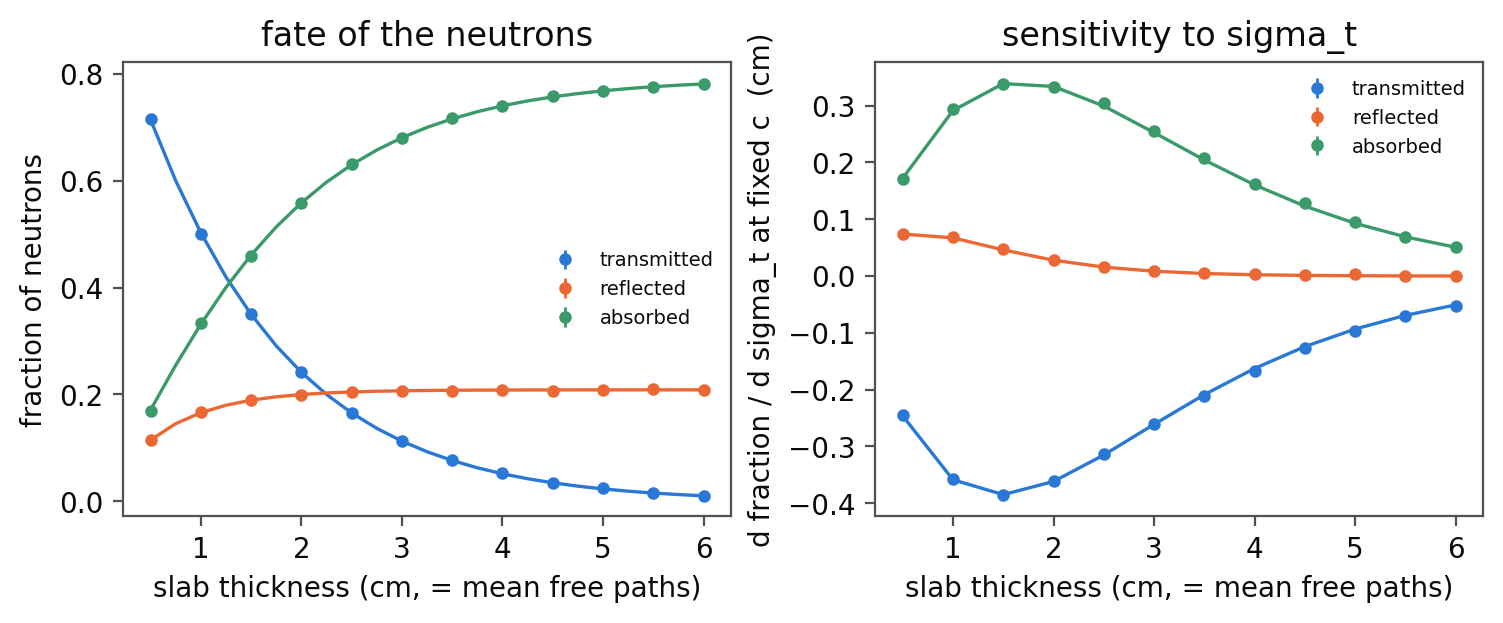
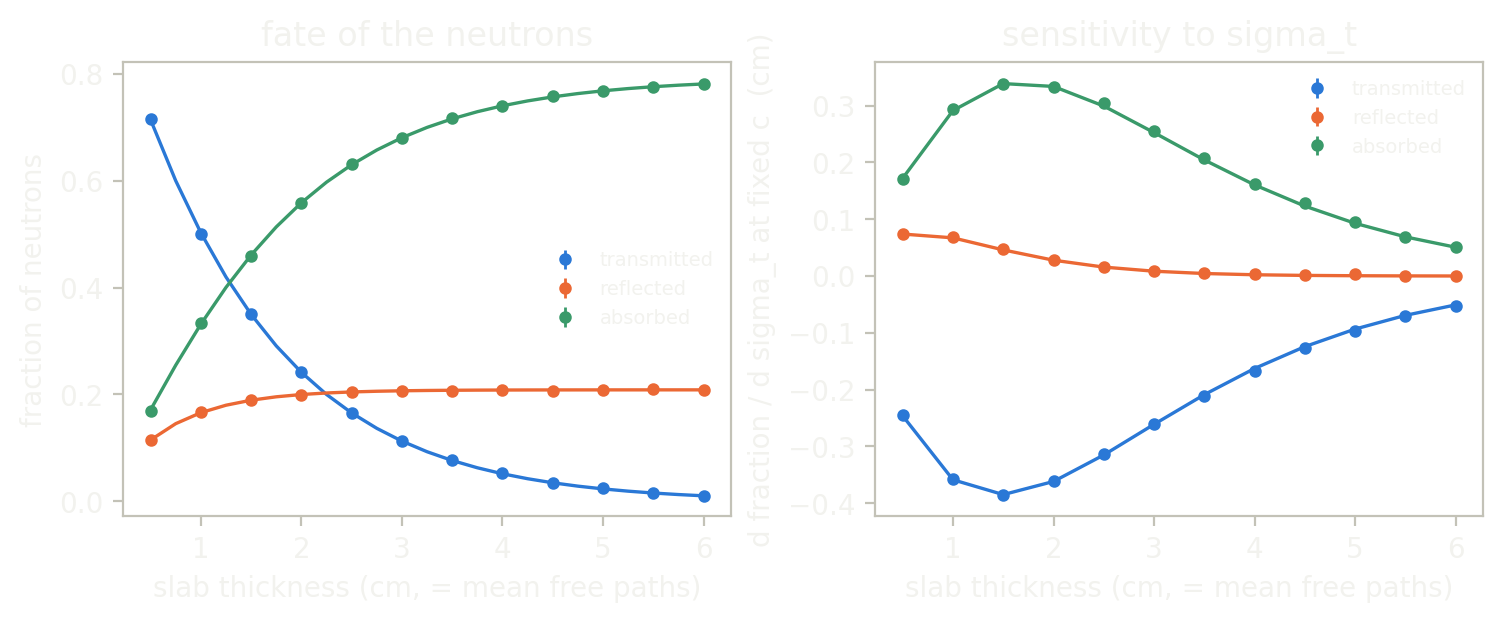

In [10]:
import matplotlib.pyplot as plt

colours = ["#2a78d6", "#eb6834", "#3a9a6a"]
names = ["transmitted", "reflected", "absorbed"]
fig, (left, right) = plt.subplots(1, 2, figsize=(7.4, 3.0), constrained_layout=True)
fine_L = np.linspace(0.5, 6, 23)
fine_ref = np.array([discrete_ordinates(L, SIGMA, C) for L in fine_L])
for j in range(3):
    left.plot(fine_L, fine_ref[:, j], lw=1.2, color=colours[j])
    left.errorbar(widths, fractions[:, j], yerr=error[:, j], fmt="o", ms=3.5, lw=1.0, color=colours[j], label=names[j])
    right.plot(widths, d_ref[:, j], lw=1.2, color=colours[j])
    right.errorbar(widths, d_est[:, j], yerr=d_err[:, j], fmt="o", ms=3.5, lw=1.0, color=colours[j], label=names[j])
left.set_xlabel("slab thickness (cm, = mean free paths)"); left.set_ylabel("fraction of neutrons"); left.set_title("fate of the neutrons")
right.set_xlabel("slab thickness (cm, = mean free paths)"); right.set_ylabel("d fraction / d sigma_t at fixed c  (cm)"); right.set_title("sensitivity to sigma_t")
left.legend(frameon=False, fontsize=7); right.legend(frameon=False, fontsize=7)
show(fig, "Two panels against slab thickness from 0.5 to 6 centimetres. Left: the transmitted fraction falls from 0.71 to about 0.01, the absorbed fraction rises from 0.17 to about 0.78, and the reflected fraction rises from 0.11 to a plateau near 0.21; dots with error bars sit on smooth reference lines. Right: the sensitivity of each fraction to the total cross-section. Transmitted is negative, with its deepest value near minus 0.38 at 1.5 centimetres; absorbed is positive with a peak near 0.34 at the same place; reflected stays between 0 and about 0.075. Dots with error bars follow the reference lines.")

## The histories, drawn

Eighty histories on a 4 cm slab with a more scattering material, `c = 0.9`, so the paths are long enough to see, drawn flight by flight. They are histories like the ones behind those fractions. The kernel `walk` is `history` again with one change: it also writes where the flight number `flight` ended, the direction it flew in and how it ended, so a call per flight number gives every history's path. It makes the same random draws as `history` on the same lanes, so the fates must match, and the check below asserts it. The slab is infinite sideways, so only `x` matters to the physics; the sideways position follows from the flight's direction cosine, with a random azimuth, to show the paths in a plane.

In [11]:
@Slab
def walk(seed, width, c, sigma_t, sigma_ref, flight: Scalar,
         x_out: Mutable[Scalar], mu_out: Mutable[Scalar], fate_out: Mutable[Scalar]):
    x = 0.0
    mu = 1.0
    alive = 1.0
    x_out = 0.0
    mu_out = 1.0
    fate_out = 9.0                                                      # 9: this history had already ended
    s = 0.0
    x_new = 0.0
    mu_flown = 1.0
    fate = 0.0
    for i in range(60):
        if alive < 0.5:
            break
        s = m.random.exponential(seed, 3 * i, sigma_ref)
        x_new = x + mu * s
        mu_flown = mu
        fate = 0.0                                                      # 0: collided and flies on
        if x_new > width:                                           # 1: out through the far face
            x_new = width
            fate = 1.0
            alive = 0.0
        elif x_new < 0.0:                                           # 2: out through the near face
            x_new = 0.0
            fate = 2.0
            alive = 0.0
        elif m.random.uniform(seed, 3 * i + 1) < c:
            mu = m.random.uniform(seed, 3 * i + 2, -1.0, 1.0)
        else:                                                       # 3: absorbed
            fate = 3.0
            alive = 0.0
        if m.abs(flight - i) < 0.5:
            x_out = x_new
            mu_out = mu_flown
            fate_out = fate
        x = x_new


H, F, L_SHOWN, C_SHOWN = 80, 60, 4.0, 0.9
walker = eagle.deploy(walk)
rows = [walker.run(seed=np.arange(H, dtype=np.int64), width=np.full(H, L_SHOWN), c=C_SHOWN, sigma_t=SIGMA, sigma_ref=SIGMA,
                   flight=np.full(H, float(f)), returns="numpy") for f in range(F)]
x_end, mu_fl, fate_at = (np.stack([r[k] for r in rows], axis=1) for k in ("x_out", "mu_out", "fate_out"))   # (history, flight)
final = np.array([fate_at[h][np.isin(fate_at[h], (1, 2, 3))][0] if np.isin(fate_at[h], (1, 2, 3)).any() else 0 for h in range(H)])
assert (final > 0).all(), "every drawn history ended within 60 flights"
tally = transport.run(seed=np.arange(H, dtype=np.int64), width=np.full(H, L_SHOWN), c=C_SHOWN, sigma_t=SIGMA, sigma_ref=SIGMA, returns="numpy")
assert np.array_equal(final == 1, tally["through"] == 1) and np.array_equal(final == 2, tally["back"] == 1) \
    and np.array_equal(final == 3, tally["absorbed"] == 1)
n_fate = [(final == k).sum() for k in (1, 2, 3)]
n_flights = (fate_at != 9).sum(axis=1)
print(f"{H} histories at {L_SHOWN:g} cm, c = {C_SHOWN:g}: {n_fate[0]} transmitted, {n_fate[1]} reflected, {n_fate[2]} absorbed;",
      f"the longest took {n_flights.max()} flights; the fates match the history kernel on the same lanes")

80 histories at 4 cm, c = 0.9: 9 transmitted, 34 reflected, 37 absorbed; the longest took 27 flights; the fates match the history kernel on the same lanes


Now the paths. Each history is a polyline from the origin through its collision points to where it ended; its colour is its fate, and the dots mark where it stopped. The sideways step of a flight of length `s` in direction `mu` is `s sqrt(1 - mu^2)`, along a random azimuth.


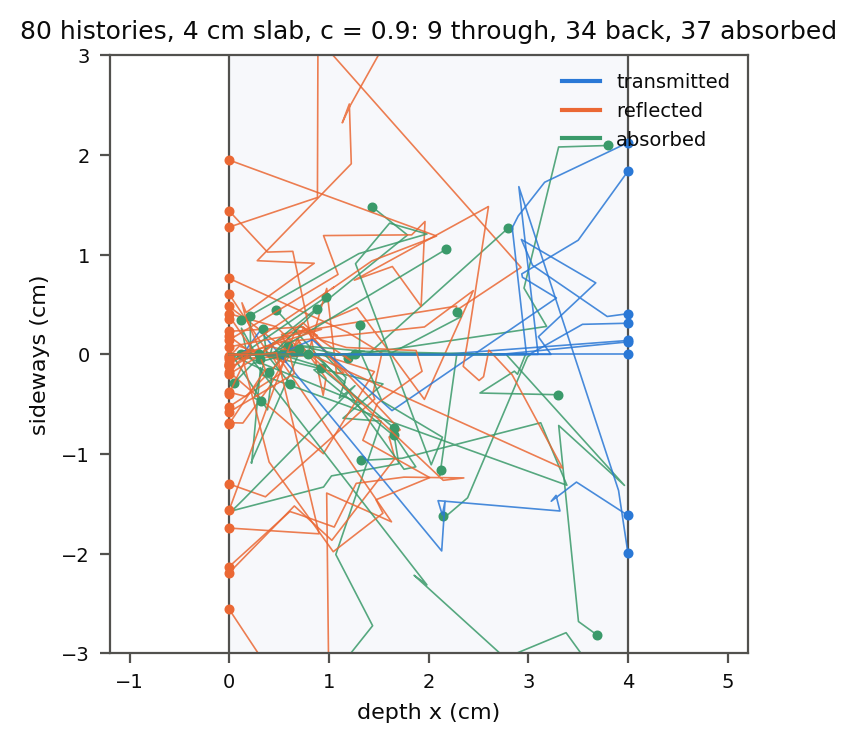
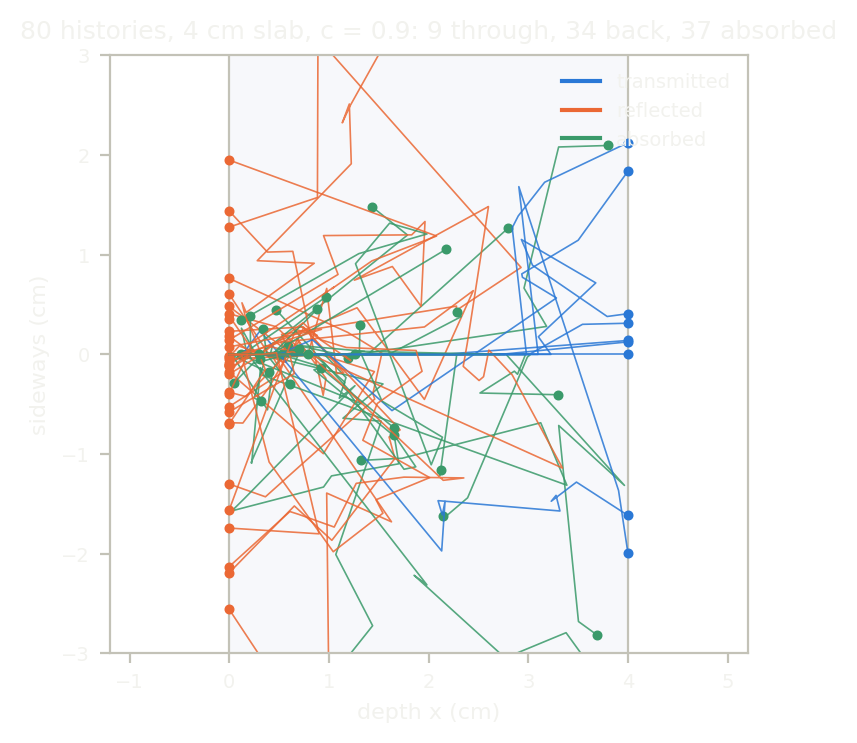

In [12]:
import matplotlib.pyplot as plt
from anim import frame_of, write_anim
from themed_figure import DARK, LIGHT

rng = np.random.default_rng(7)
paths = []                                                       # per history: vertices (x, y), one per flight end
for h in range(H):
    n = n_flights[h]
    dx = np.diff(np.r_[0.0, x_end[h, :n]])
    side = np.abs(dx) * np.sqrt(1 - mu_fl[h, :n] ** 2) / np.maximum(np.abs(mu_fl[h, :n]), 1e-9)
    y = np.cumsum(side * np.cos(rng.uniform(0, 2 * np.pi, n)))
    paths.append(np.column_stack([np.r_[0.0, x_end[h, :n]], np.r_[0.0, y]]))
FATE_COLOUR = {1: "#2a78d6", 2: "#eb6834", 3: "#3a9a6a"}
FATE_NAME = {1: "transmitted", 2: "reflected", 3: "absorbed"}
Y_LIM = 3.0


def draw(ax, pal, t=None):
    """The slab and the paths; with ``t`` (flights completed, fractional), each path only as far as it has got."""
    ax.set_facecolor(pal["bg"])
    ax.axvspan(0, L_SHOWN, color=pal["grid"], alpha=0.35, lw=0)
    ax.axvline(0, color=pal["sub"], lw=0.8); ax.axvline(L_SHOWN, color=pal["sub"], lw=0.8)
    flying = 0
    for h, P in enumerate(paths):
        k = len(P) - 1 if t is None else min(len(P) - 1, int(np.floor(t)))
        pts = P[: k + 1]
        if t is not None and k < len(P) - 1:                         # the flight in progress, part way
            f = t - k
            pts = np.vstack([pts, pts[-1] + f * (P[k + 1] - P[k])])
            flying += 1
        ended = k == len(P) - 1
        ax.plot(pts[:, 0], pts[:, 1], lw=0.6, color=FATE_COLOUR[final[h]], alpha=0.85)
        if ended:
            ax.plot(*pts[-1], "o", ms=2.6, color=FATE_COLOUR[final[h]])
    ax.set_xlim(-1.2, L_SHOWN + 1.2); ax.set_ylim(-Y_LIM, Y_LIM); ax.set_aspect("equal")
    ax.set_xlabel("depth x (cm)", color=pal["sub"], fontsize=8); ax.set_ylabel("sideways (cm)", color=pal["sub"], fontsize=8)
    ax.tick_params(colors=pal["sub"], labelsize=7)
    for sp in ax.spines.values():
        sp.set_color(pal["rule"])
    return flying


fig, ax = plt.subplots(figsize=(6.4, 3.6), constrained_layout=True)
draw(ax, LIGHT)
ax.set_title(f"{H} histories, {L_SHOWN:g} cm slab, c = {C_SHOWN:g}: {n_fate[0]} through, {n_fate[1]} back, {n_fate[2]} absorbed", fontsize=9)
for k in (1, 2, 3):
    ax.plot([], [], color=FATE_COLOUR[k], lw=1.5, label=FATE_NAME[k])
ax.legend(frameon=False, fontsize=7, loc="upper right")
show(fig, f"{H} neutron paths enter a slab from the left. {n_fate[0]} leave through the far face, {n_fate[1]} come back out of the near face and {n_fate[2]} are absorbed inside; each path is a line of straight flights joined at collisions, coloured by how it ended.")

## The animation

The same paths, drawn as the flights happen: every neutron flies one straight leg, collides, and flies on, until it leaves or is absorbed. The count says how many are still flying. The helper that writes a looping GIF for a light page and one for a dark page is shared with the other domain pages.

In [13]:
def render(theme, t):
    pal = LIGHT if theme == "light" else DARK
    fig = plt.figure(figsize=(5.0, 3.0), facecolor=pal["bg"])
    ax = fig.add_axes([0.10, 0.17, 0.86, 0.76])
    flying = draw(ax, pal, t)
    ax.text(0.99, 0.95, f"{flying} of {H} still flying", transform=ax.transAxes, ha="right", va="top", fontsize=8, color=pal["ink"])
    return frame_of(fig, pal["bg"])


ts = np.r_[np.arange(0, n_flights.max() + 0.01, 0.5 if n_flights.max() <= 30 else 1.0), np.full(8, n_flights.max())]
sizes = {}
for theme in ("light", "dark"):
    sizes.update(write_anim([render(theme, t) for t in ts], f"neutron_histories_{theme}", fps=8))
for name, size in sizes.items():
    print(name, f"{size / 1e3:.0f} kB")
assert max(sizes.values()) < 1.5e6

neutron_histories_light.gif 374 kB
neutron_histories_dark.gif 324 kB


```{image} ../../_static/anim/neutron_histories_light.gif
:class: only-light
:alt: Eighty neutron paths cross a slab from the left, growing one straight flight at a time; blue ones leave through the far face, orange ones leave back through the near face, green ones stop inside, and a counter shows how many are still flying
```
```{image} ../../_static/anim/neutron_histories_dark.gif
:class: only-dark
:alt: Eighty neutron paths cross a slab from the left, growing one straight flight at a time; blue ones leave through the far face, orange ones leave back through the near face, green ones stop inside, and a counter shows how many are still flying
```

## A bigger run, when a GPU is there

This cell runs only when a GPU is present; on a CPU runtime it prints that and does nothing. The same kernel and the same call run on device arrays: four million histories at 2 cm. The fractions must agree with the deterministic solution within four standard errors; one standard error is about 2e-4.

In [14]:
if gpu_available():
    big = 4_000_000
    got = transport.run(seed=xp.arange(big, dtype=xp.int64) + 10**9, width=xp.full(big, 2.0), c=C, sigma_t=SIGMA, sigma_ref=SIGMA)
    assert on_device(got["through"]), "the result is a device array: the kernel ran on the GPU"
    assert float(to_numpy(got["unfinished"]).max()) == 0.0
    f = np.array([float(to_numpy(got[k]).mean()) for k in ("through", "back", "absorbed")])
    sd = np.sqrt(reference[3] * (1 - reference[3]) / big)
    assert (np.abs(f - reference[3]) < Z_MAX * sd).all(), (f, reference[3])
    print(f"{big} histories on the GPU: fractions {f.round(4)} against {reference[3].round(4)}, within {Z_MAX:g} standard errors")
else:
    print("no GPU here; the sweep stays at", K * N, "histories")

4000000 histories on the GPU: fractions [0.2413 0.2004 0.5584] against [0.2415 0.2    0.5586], within 4 standard errors


## What just happened

- `Slab` named the history number, the thickness and the cross-sections once; `history` is one neutron's life in those names, with `if / elif / else` on what the flight did and a second branch on the collision.
- The counter-based generator made every history reproducible, and the same random numbers served runs at different cross-sections.
- The transmitted fraction of a purely absorbing slab matched `exp(-sigma_t width)` and the scattering slab matched a deterministic solution, both within the stated number of standard errors; the spread of independent batches fell as `1 / sqrt(N)`.
- The likelihood ratio `w` turned the jump in each tally into a smooth function of `sigma_t`; `jvp` differentiated it, the result matched a finite difference of the same tallies to rounding, and matched the reference derivative, a common-random-numbers difference and the closed form within their errors.
- `walk` wrote each flight's end from the same random draws, so the eighty paths drawn are the histories the tallies counted, with the same fates.

## Try this

Raise the scattering ratio `c` toward 1 and watch the reflected fraction grow at the cost of the absorbed one; the history limit of 120 collisions is the first thing to check, through `unfinished`. Or differentiate with respect to `c` instead: add `c` to `wrt`, and give the collision branch its own likelihood ratio.

## Next

[Monte Carlo](12_monte_carlo_ensemble) ends a batch of samples as each one lands. [Combustion](13_combustion) takes a gradient through a stop in a runaway reaction.